# Two-Group Comparisons

When comparing **two groups**, we choose the statistical test based on:
1. **Data type** – continuous or categorical
2. **Independence** – independent or paired samples
3. **Assumptions** – normal distribution, equal variances

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Parametric Case (t-tests)

### Independent samples (Student's) t-test
If $X_1, \dots, X_n \sim N(\mu_1, \sigma^2)$ and $Y_1, \dots, Y_m \sim N(\mu_2, \sigma^2)$, we test $H_0 : \mu_1 = \mu_2$ with

$$
t = \frac{\bar{X} - \bar{Y}}{s_p \sqrt{\frac{1}{n} + \frac{1}{m}}}, \qquad
s_p = \sqrt{\frac{(n-1)s_X^2 + (m-1)s_Y^2}{n+m-2}}, \qquad df = n + m - 2
$$

### Welch's t-test (unequal variances)
$$
t = \frac{\bar{X} - \bar{Y}}{\sqrt{\frac{s_X^2}{n} + \frac{s_Y^2}{m}}}
$$
with the Welch–Satterthwaite degrees of freedom. It is R's **default** in `t.test()`.

### Paired t-test
For paired data $(X_i, Y_i)$, define $D_i = X_i - Y_i$ and test $H_0 : \mu_D = 0$:
$$
t = \frac{\bar{D}}{s_D / \sqrt{n}}, \qquad df = n - 1
$$

## 2. Non-parametric Case

- **Mann–Whitney U test** (= Wilcoxon rank-sum): compares rank sums between two independent groups.
$$
U_X = R_X - \frac{n_X(n_X + 1)}{2}
$$
  where $R_X$ is the sum of the ranks of group $X$ in the pooled sample.
- **Wilcoxon signed-rank test**: for paired data; ranks the absolute differences $|D_i|$ and compares the positive and negative rank totals.

## 3. Effect Size: Cohen's d

A p-value says *whether* there is a difference; **Cohen's d** says *how big* it is, in standard-deviation units:
$$
d = \frac{\bar{X} - \bar{Y}}{s_p} \qquad (0.2 \text{ small}, \; 0.5 \text{ medium}, \; 0.8 \text{ large})
$$

## 4. Independent Samples: Student vs Welch

Two teaching methods; 25 students each. Method B's scores are more variable.

In [2]:
set.seed(11)
method_A <- rnorm(25, mean = 70, sd = 6)
method_B <- rnorm(25, mean = 76, sd = 10)

cat("Means:", round(mean(method_A), 2), "vs", round(mean(method_B), 2),
    "| SDs:", round(sd(method_A), 2), "vs", round(sd(method_B), 2), "\n")

student <- t.test(method_A, method_B, var.equal = TRUE)
welch   <- t.test(method_A, method_B)            # Welch is the default

cohens_d <- function(x, y) {
  sp <- sqrt(((length(x) - 1) * var(x) + (length(y) - 1) * var(y)) / (length(x) + length(y) - 2))
  (mean(x) - mean(y)) / sp
}

data.frame(test = c("Student t-test", "Welch t-test"),
           t = round(c(student$statistic, welch$statistic), 3),
           df = round(c(student$parameter, welch$parameter), 1),
           p_value = signif(c(student$p.value, welch$p.value), 3))
cat("Cohen's d =", round(cohens_d(method_A, method_B), 3), "\n")

Means: 68.15 vs 73.4 | SDs: 4.67 vs 9.17 


test,t,df,p_value
<chr>,<dbl>,<dbl>,<dbl>
Student t-test,-2.553,48.0,0.0139
Welch t-test,-2.553,35.6,0.0151


Cohen's d = -0.722 


In [3]:
welch


	Welch Two Sample t-test

data:  method_A and method_B
t = -2.5527, df = 35.647, p-value = 0.01512
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -9.428564 -1.078120
sample estimates:
mean of x mean of y 
 68.15027  73.40361 


## 5. Paired Samples: Before vs After

Eight people measured before and after a training programme. The **same person** appears in both columns, so the samples are paired.

In [4]:
set.seed(102)
before <- rnorm(8, mean = 70, sd = 8)    # people differ a lot from each other
after  <- before + rnorm(8, mean = 3, sd = 2)

paired_res <- t.test(after, before, paired = TRUE)
paired_res

# What happens if we (wrongly) ignore the pairing?
wrong <- t.test(after, before)
cat("Paired p-value  :", signif(paired_res$p.value, 3), "\n")
cat("Unpaired p-value:", signif(wrong$p.value, 3), " <- pairing ignored: the same data now looks like noise\n")


	Paired t-test

data:  after and before
t = 4.559, df = 7, p-value = 0.002608
alternative hypothesis: true mean difference is not equal to 0
95 percent confidence interval:
 1.639847 5.174028
sample estimates:
mean difference 
       3.406937 


Paired p-value  : 0.00261 


Unpaired p-value: 0.381  <- pairing ignored: the same data now looks like noise


## 6. Non-parametric Tests for Skewed Data

In [5]:
set.seed(202)
wait_store1 <- rexp(15, rate = 0.2)    # mean waiting time 5 minutes
wait_store2 <- rexp(15, rate = 0.5)    # mean waiting time 2 minutes
mw_res <- wilcox.test(wait_store1, wait_store2)
mw_res

set.seed(303)
sk_before <- rexp(10, rate = 0.3)
sk_after  <- sk_before + rexp(10, rate = 0.4)
wilcoxon_res <- wilcox.test(sk_after, sk_before, paired = TRUE)
wilcoxon_res


	Wilcoxon rank sum exact test

data:  wait_store1 and wait_store2
W = 208, p-value = 1.555e-05
alternative hypothesis: true location shift is not equal to 0



	Wilcoxon signed rank exact test

data:  sk_after and sk_before
V = 55, p-value = 0.001953
alternative hypothesis: true location shift is not equal to 0


## 7. Visualising Two-Group Comparisons

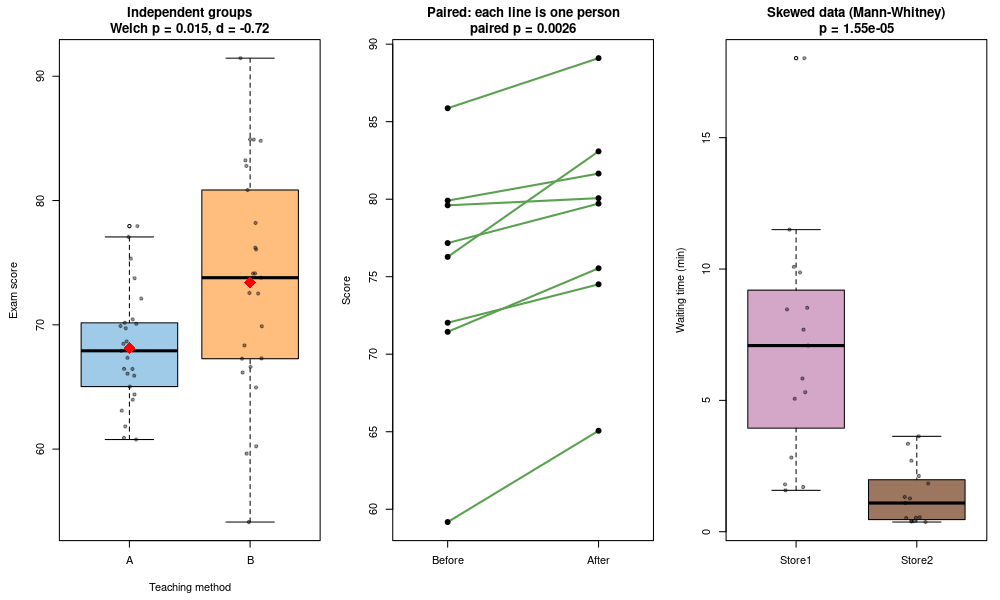

In [6]:
par(mfrow = c(1, 3), mar = c(4.5, 4.5, 3, 1))

boxplot(list(A = method_A, B = method_B), col = c("#A0CBE8", "#FFBE7D"),
        main = sprintf("Independent groups\nWelch p = %.3f, d = %.2f", welch$p.value, cohens_d(method_A, method_B)),
        ylab = "Exam score", xlab = "Teaching method")
stripchart(list(method_A, method_B), vertical = TRUE, method = "jitter", pch = 19,
           col = adjustcolor("black", 0.4), add = TRUE)
points(1:2, c(mean(method_A), mean(method_B)), pch = 18, cex = 2.5, col = "red")

plot(NA, xlim = c(0.7, 2.3), ylim = range(c(before, after)), xaxt = "n",
     main = sprintf("Paired: each line is one person\npaired p = %.4f", paired_res$p.value),
     xlab = "", ylab = "Score")
axis(1, at = 1:2, labels = c("Before", "After"))
segments(1, before, 2, after, col = ifelse(after > before, "#59A14F", "#E15759"), lwd = 2)
points(rep(1, 8), before, pch = 19); points(rep(2, 8), after, pch = 19)

boxplot(list(Store1 = wait_store1, Store2 = wait_store2), col = c("#D4A6C8", "#9D7660"),
        main = paste0("Skewed data (Mann-Whitney)\np = ", format.pval(mw_res$p.value, digits = 3)),
        ylab = "Waiting time (min)")
stripchart(list(wait_store1, wait_store2), vertical = TRUE, method = "jitter", pch = 19,
           col = adjustcolor("black", 0.4), add = TRUE)

*Insight: In the paired plot almost every line goes **up**. Each person improved by a few points, but people differ from each other by much more than that. An unpaired test drowns the improvement in that between-person variation; the paired test removes it by looking only at each person's difference.*

## Real-World Use Case or Analogy

- **Independent t-test**: compare average exam scores between **two different classes**.
- **Welch t-test**: the same, when one class's scores are much more spread out than the other's.
- **Paired t-test**: compare the **same students' scores before and after** a special training programme.
- **Mann–Whitney U**: compare two stores' customer waiting times, which are skewed (most are short, a few are very long).
- **Wilcoxon signed-rank**: compare before/after measurements on the same people when the differences are not normal.

An A/B test on a website is a two-group comparison: version A vs version B, independent visitors, often with skewed metrics such as time on page.